In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


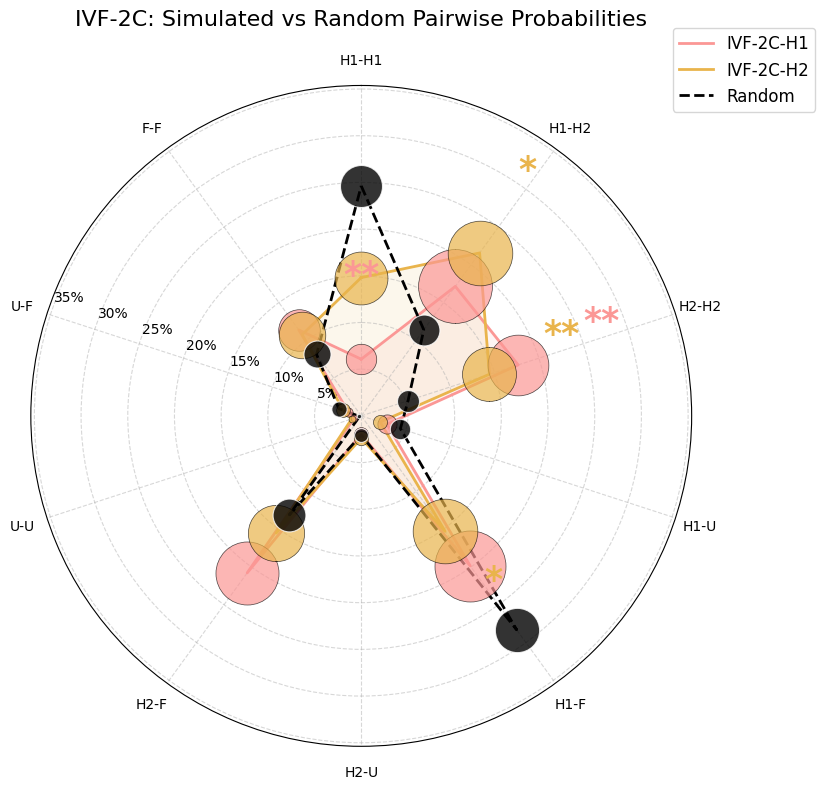

In [3]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

# =============================
# 1. 读取模拟数据（H1 和 H2）
# =============================
df_h1 = pd.read_csv("IVF-2C-H1-p.txt", sep="\t")
df_h2 = pd.read_csv("IVF-2C-H2-p.txt", sep="\t")

pair_names = df_h1.columns[1:].tolist()          # 转为列表，避免 index 错误
sim_matrix_h1 = df_h1[pair_names].values
sim_matrix_h2 = df_h2[pair_names].values

# =============================
# 2. 理论随机分布
# =============================
p_dict = {'H1': 0.4702, 'H2': 0.2175, 'U': 0.0421, 'F': 0.2702}
categories = list(p_dict.keys())
pair_probs = {}
for i, j in itertools.combinations_with_replacement(categories, 2):
    prob = (p_dict[i] ** 2) if i == j else 2 * p_dict[i] * p_dict[j]
    key = f"{i}-{j}"
    pair_probs[key] = prob

raw_probs = np.array([pair_probs[p] for p in pair_names])
random_prob = raw_probs / raw_probs.sum()

# =============================
# 3. 模拟均值与标准差
# =============================
sim_mean_h1 = sim_matrix_h1.mean(axis=0)
sim_mean_h2 = sim_matrix_h2.mean(axis=0)
std_h1 = sim_matrix_h1.std(axis=0)
std_h2 = sim_matrix_h2.std(axis=0)

# =============================
# 4. 显著性检验
# =============================
n_rep = sim_matrix_h1.shape[0]
n_sim = 10000
null_matrix = np.random.multinomial(n=n_rep, pvals=random_prob, size=n_sim) / n_rep
null_std = null_matrix.std(axis=0)

p_values_h1, p_values_h2 = [], []
for i in range(len(pair_names)):
    obs1 = sim_matrix_h1[:, i]
    obs2 = sim_matrix_h2[:, i]
    null = null_matrix[:, i]
    p1 = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs1.mean() - random_prob[i]))
    p2 = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs2.mean() - random_prob[i]))
    p_values_h1.append(p1)
    p_values_h2.append(p2)

def sig_star(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    return ""

sig_labels_h1 = [sig_star(p) for p in p_values_h1]
sig_labels_h2 = [sig_star(p) for p in p_values_h2]

# =============================
# 5. 颜色定义
# =============================
color_h1 = '#fb9795'
color_h2 = '#E9B44C'
light_h1 = '#fb9795'
lighter_h1 = '#fb9795'
light_h2 = '#E9B44C'
lighter_h2 = '#E9B44C'

        
def get_color_group(pair_name):
    if pair_name in ['H1-U', 'H1-F', 'H2-U', 'H2-F']:
        return 'light'
    elif pair_name in ['U-U', 'U-F', 'F-F']:
        return 'lighter'
    else:
        return 'primary'

def get_point_color(pair_name, base_color):
    group = get_color_group(pair_name)
    if base_color == color_h1:
        return light_h1 if group == 'light' else lighter_h1 if group == 'lighter' else color_h1
    else:
        return light_h2 if group == 'light' else lighter_h2 if group == 'lighter' else color_h2

# =============================
# 6. 雷达图绘制
# =============================
angles = np.linspace(0, 2 * np.pi, len(pair_names), endpoint=False).tolist()
angles += angles[:1]

values_h1 = sim_mean_h1.tolist() + sim_mean_h1[:1].tolist()
values_h2 = sim_mean_h2.tolist() + sim_mean_h2[:1].tolist()
values_rand = random_prob.tolist() + random_prob[:1].tolist()

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': 'polar'})

# ----- 不再旋转整个图，保持默认起始角度（第一个配对在右侧） -----
ax.set_theta_offset(np.pi / 2)   # 保持原有风格（或注释掉，采用默认）
ax.set_theta_direction(-1)

# 绘制线条和填充
ax.plot(angles, values_h1, linewidth=2, label='IVF-2C-H1', color=color_h1)
ax.fill(angles, values_h1, alpha=0.1, color=color_h1)
ax.plot(angles, values_h2, linewidth=2, label='IVF-2C-H2', color=color_h2)
ax.fill(angles, values_h2, alpha=0.1, color=color_h2)
ax.plot(angles, values_rand, '--', linewidth=2, label='Random', color='black')

# 绘制数据点（圆圈大小表示标准差）
scale = 500
for i, angle in enumerate(angles[:-1]):
    s1 = (std_h1[i] * scale) ** 2
    ax.scatter(angle, sim_mean_h1[i], s=s1, color=get_point_color(pair_names[i], color_h1),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    s2 = (std_h2[i] * scale) ** 2
    ax.scatter(angle, sim_mean_h2[i], s=s2, color=get_point_color(pair_names[i], color_h2),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    s_rand = (null_std[i] * scale) ** 2
    ax.scatter(angle, random_prob[i], s=s_rand, color='black',
               edgecolor='white', linewidth=0.8, alpha=0.8, zorder=5)

# 显著性星号（置于顶层，放大）
for i, (angle, sig1, sig2) in enumerate(zip(angles[:-1], sig_labels_h1, sig_labels_h2)):
    if sig1:
        r_pos = sim_mean_h1[i] + 0.05 + std_h1[i] * 0.5
        ax.text(angle, r_pos, sig1, ha='center', va='bottom',
                fontsize=25, color=color_h1, weight='bold', zorder=10)
    if sig2:
        r_pos = sim_mean_h2[i] + 0.05 + std_h2[i] * 0.4
        ax.text(angle, r_pos, sig2, ha='center', va='bottom',
                fontsize=25, color=color_h2, weight='bold', zorder=10)

# 设置 x 轴刻度（配对标签）
ax.set_xticks(angles[:-1])
ax.set_xticklabels(pair_names, fontsize=10, ha='center', va='center')
ax.tick_params(axis='x', pad=8)

# 设置 y 轴百分比格式
def perc_formatter(x, pos):
    return f'{x*100:.0f}%'
ax.yaxis.set_major_formatter(FuncFormatter(perc_formatter))
ax.yaxis.set_tick_params(pad=15, labelsize=10)

ax.set_rlabel_position(290)  
# ========================================================

# 扩大 y 轴上限
max_val = max(max(values_h1), max(values_h2), max(values_rand))
ax.set_ylim(0, max_val * 1.25)

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=12)
plt.title('IVF-2C: Simulated vs Random Pairwise Probabilities', fontsize=16, pad=20)

plt.tight_layout()
plt.savefig("IVF_2C_Radar_circles.svg", dpi=300, transparent=True)
plt.show()

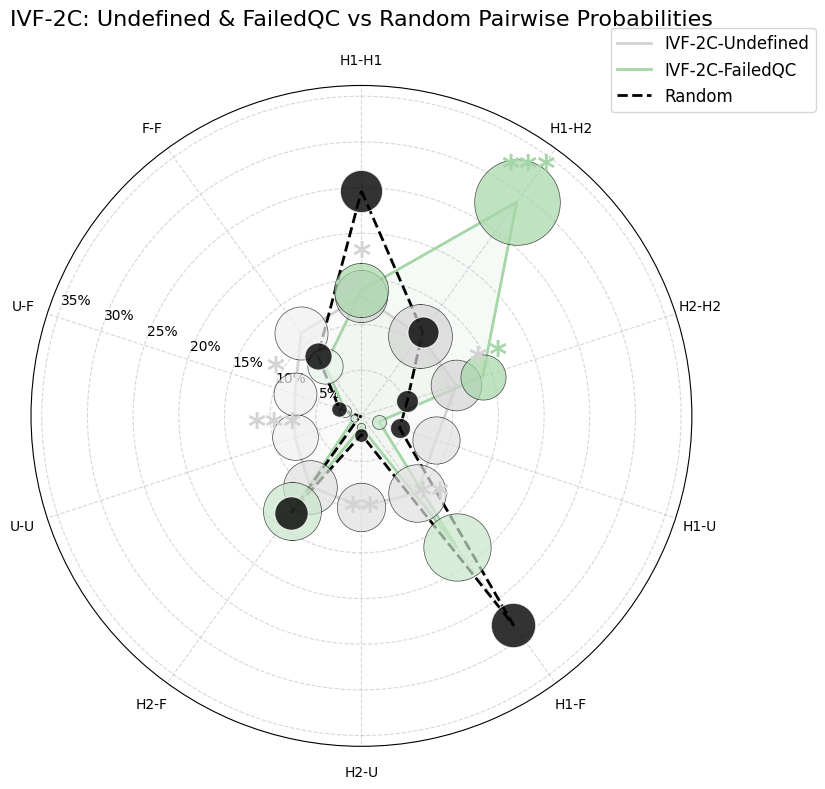


===== 各类别概率之和 =====
Pair Type    Undefined Sim  FailedQC Sim   Random Sum  
----------------------------------------------------
H1-H1         13.17%         13.75%         24.63%
H1-H2         10.86%         28.94%         11.39%
H2-H2         10.91%         13.95%          5.27%
H1-U           8.55%          2.03%          4.41%
H1-F          10.44%         17.75%         28.30%
H2-U           9.92%          1.24%          2.04%
H2-F           9.59%         12.85%         13.09%
U-U            7.66%          0.86%          0.20%
U-F            7.67%          1.84%          2.53%
F-F           11.22%          6.78%          8.13%

全局总和验证:
Undefined 所有类别概率和: 1.000000 (应为1)
FailedQC 所有类别概率和: 1.000000 (应为1)
随机所有类别概率和: 1.000000 (应为1)


In [66]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

# =============================
# 1. 读取模拟数据（Undefined 和 FailedQC）
# =============================
df_u = pd.read_csv("IVF-2C-U-p.txt", sep="\t")      # Undefined
df_f = pd.read_csv("IVF-2C-F-p.txt", sep="\t")      # FailedQC

pair_names = df_u.columns[1:].tolist()   # 转为列表，确保索引可用
sim_matrix_u = df_u[pair_names].values
sim_matrix_f = df_f[pair_names].values

# =============================
# 2. 理论随机分布
# =============================
p_dict = {'H1': 0.4702, 'H2': 0.2175, 'U': 0.0421, 'F': 0.2702}

categories = list(p_dict.keys())
pair_probs = {}
for i, j in itertools.combinations_with_replacement(categories, 2):
    prob = (p_dict[i] ** 2) if i == j else 2 * p_dict[i] * p_dict[j]
    key = f"{i}-{j}"
    pair_probs[key] = prob

raw_probs = np.array([pair_probs[p] for p in pair_names])
random_prob = raw_probs / raw_probs.sum()

# =============================
# 3. 模拟均值和标准差
# =============================
sim_mean_u = sim_matrix_u.mean(axis=0)
sim_mean_f = sim_matrix_f.mean(axis=0)
std_u = sim_matrix_u.std(axis=0)
std_f = sim_matrix_f.std(axis=0)

# 生成随机模拟矩阵（用于计算随机标准差）
n_rep = sim_matrix_u.shape[0]
n_sim = 10000
null_matrix = np.random.multinomial(n=n_rep, pvals=random_prob, size=n_sim) / n_rep
null_std = null_matrix.std(axis=0)

# =============================
# 4. 显著性检验
# =============================
p_values_u = []
p_values_f = []
for i in range(len(pair_names)):
    obs_u = sim_matrix_u[:, i]
    obs_f = sim_matrix_f[:, i]
    null = null_matrix[:, i]
    p_u = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs_u.mean() - random_prob[i]))
    p_f = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs_f.mean() - random_prob[i]))
    p_values_u.append(p_u)
    p_values_f.append(p_f)

def sig_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""

sig_labels_u = [sig_star(p) for p in p_values_u]
sig_labels_f = [sig_star(p) for p in p_values_f]

# =============================
# 5. 颜色设定（lightgrey 和 #A5D6A7）
# =============================
def get_color_group(pair_name):
    if pair_name in ['H1-U', 'H1-F', 'H2-U', 'H2-F']:
        return 'light'
    elif pair_name in ['U-U', 'U-F', 'F-F']:
        return 'lighter'
    else:
        return 'primary'

color_u = 'lightgrey'          # Undefined 主色
color_f = '#A5D6A7'            # FailedQC 主色（浅绿）

light_u = '#E0E0E0'            # 浅灰
lighter_u = '#F0F0F0'          # 更浅灰
light_f = '#C8E6C9'            # 浅绿
lighter_f = '#E8F5E9'          # 更浅绿

def get_point_color(pair_name, base_color):
    group = get_color_group(pair_name)
    if base_color == color_u:
        if group == 'light':
            return light_u
        elif group == 'lighter':
            return lighter_u
        else:
            return base_color
    else:
        if group == 'light':
            return light_f
        elif group == 'lighter':
            return lighter_f
        else:
            return base_color

# =============================
# 6. 绘制雷达图（画风与第一个图一致）
# =============================
angles = np.linspace(0, 2 * np.pi, len(pair_names), endpoint=False).tolist()
angles += angles[:1]   # 闭合

values_u = sim_mean_u.tolist() + sim_mean_u[:1].tolist()
values_f = sim_mean_f.tolist() + sim_mean_f[:1].tolist()
values_rand = random_prob.tolist() + random_prob[:1].tolist()

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': 'polar'})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# 绘制均值折线 + 填充
ax.plot(angles, values_u, linewidth=2, label='IVF-2C-Undefined', color=color_u)
ax.fill(angles, values_u, alpha=0.1, color=color_u)
ax.plot(angles, values_f, linewidth=2, label='IVF-2C-FailedQC', color=color_f)
ax.fill(angles, values_f, alpha=0.1, color=color_f)
ax.plot(angles, values_rand, '--', linewidth=2, label='Random', color='black')

# ---------- 圆圈：大小表示标准差 ----------
scale = 500
for i, angle in enumerate(angles[:-1]):
    # Undefined 圆圈
    s_u = (std_u[i] * scale) ** 2
    ax.scatter(angle, sim_mean_u[i], s=s_u,
               color=get_point_color(pair_names[i], color_u),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    # FailedQC 圆圈
    s_f = (std_f[i] * scale) ** 2
    ax.scatter(angle, sim_mean_f[i], s=s_f,
               color=get_point_color(pair_names[i], color_f),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    # Random 圆圈
    s_rand = (null_std[i] * scale) ** 2
    ax.scatter(angle, random_prob[i], s=s_rand,
               color='black', edgecolor='white', linewidth=0.8, alpha=0.8, zorder=5)

# ---------- 显著性星号（放大，置于顶层，动态偏移） ----------
for i, (angle, sig1, sig2) in enumerate(zip(angles[:-1], sig_labels_u, sig_labels_f)):
    if sig1:
        r_pos = sim_mean_u[i] + 0.01 + std_u[i] * 0.2
        ax.text(angle, r_pos, sig1, ha='center', va='bottom',
                fontsize=25, color=color_u, weight='bold', zorder=20)
    if sig2:
        r_pos = sim_mean_f[i] + 0.01 + std_f[i] * 0.1
        ax.text(angle, r_pos, sig2, ha='center', va='bottom',
                fontsize=25, color=color_f, weight='bold', zorder=20)

# 坐标轴设置
ax.set_xticks(angles[:-1])
ax.set_xticklabels(pair_names, fontsize=10, ha='center', va='center')
ax.tick_params(axis='x', pad=8)

def perc_formatter(x, pos):
    return f'{x*100:.0f}%'
ax.yaxis.set_major_formatter(FuncFormatter(perc_formatter))
ax.yaxis.set_tick_params(pad=15, labelsize=10)

ax.set_rlabel_position(290)  

# 扩大 y 轴上限，给星号留出空间
max_val = max(max(values_u), max(values_f), max(values_rand))
ax.set_ylim(0, max_val * 1.25)

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=12)
plt.title('IVF-2C: Undefined & FailedQC vs Random Pairwise Probabilities', fontsize=16, pad=20)

plt.tight_layout()
plt.savefig("IVF_2C_Radar_U_F_circles.svg", dpi=300, transparent=True)
plt.show()

# =============================
# 7. 打印概率和（不变）
# =============================
print("\n===== 各类别概率之和 =====")
print(f"{'Pair Type':<12} {'Undefined Sim':<14} {'FailedQC Sim':<14} {'Random Sum':<12}")
print("-" * 52)
for i, pair in enumerate(pair_names):
    u_sum = sim_mean_u[i]
    f_sum = sim_mean_f[i]
    rand_sum = random_prob[i]
    print(f"{pair:<12} {u_sum*100:>6.2f}%        {f_sum*100:>6.2f}%        {rand_sum*100:>6.2f}%")

print("\n全局总和验证:")
print(f"Undefined 所有类别概率和: {sim_mean_u.sum():.6f} (应为1)")
print(f"FailedQC 所有类别概率和: {sim_mean_f.sum():.6f} (应为1)")
print(f"随机所有类别概率和: {random_prob.sum():.6f} (应为1)")

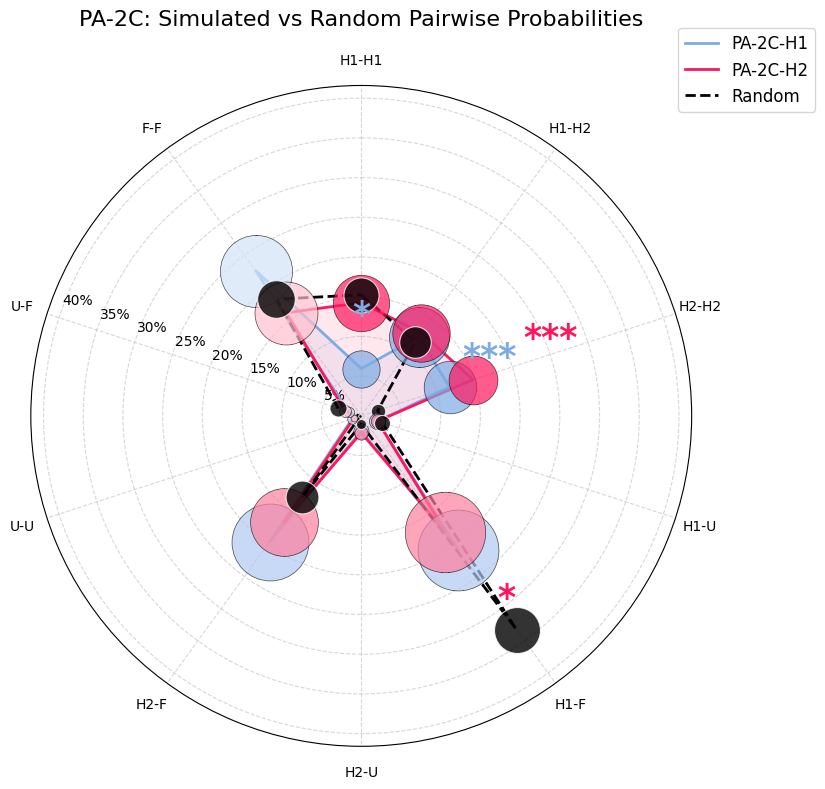


===== 各类别概率之和 =====
Pair Type    H1 Sim Sum   H2 Sim Sum   Random Sum  
------------------------------------------------
H1-H1          5.95%        14.25%        15.25%
H1-H2         12.32%        12.89%        11.55%
H2-H2         11.70%        14.79%         2.19%
H1-U           2.15%         2.16%         2.77%
H1-F          20.82%        18.04%        33.28%
H2-U           1.94%         2.13%         1.05%
H2-F          19.61%        16.56%        12.60%
U-U            1.22%         1.00%         0.13%
U-F            1.68%         2.14%         3.03%
F-F           22.61%        16.04%        18.15%

全局总和验证:
H1 所有类别概率和: 1.000000 (应为1)
H2 所有类别概率和: 1.000000 (应为1)
随机所有类别概率和: 1.000000 (应为1)


In [73]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

# =============================
# 1. 读取模拟数据（H1 和 H2）
# =============================
df_h1 = pd.read_csv("PA-2C-H1-p.txt", sep="\t")
df_h2 = pd.read_csv("PA-2C-H2-p.txt", sep="\t")

pair_names = df_h1.columns[1:].tolist()          # 转为列表，避免 index 错误
sim_matrix_h1 = df_h1[pair_names].values
sim_matrix_h2 = df_h2[pair_names].values

# =============================
# 2. 理论随机分布
# =============================
p_dict = {'H1': 0.3905, 'H2': 0.1479, 'U': 0.0355, 'F': 0.4260}

categories = list(p_dict.keys())
pair_probs = {}
for i, j in itertools.combinations_with_replacement(categories, 2):
    prob = (p_dict[i] ** 2) if i == j else 2 * p_dict[i] * p_dict[j]
    pair_probs[f"{i}-{j}"] = prob

raw_probs = np.array([pair_probs[p] for p in pair_names])
random_prob = raw_probs / raw_probs.sum()   # 随机对照

# =============================
# 3. 模拟均值和标准差
# =============================
sim_mean_h1 = sim_matrix_h1.mean(axis=0)
sim_mean_h2 = sim_matrix_h2.mean(axis=0)
std_h1 = sim_matrix_h1.std(axis=0)
std_h2 = sim_matrix_h2.std(axis=0)

# =============================
# 4. 显著性检验 + 计算随机标准差
# =============================
n_rep = sim_matrix_h1.shape[0]
n_sim = 10000
null_matrix = np.random.multinomial(n=n_rep, pvals=random_prob, size=n_sim) / n_rep
null_std = null_matrix.std(axis=0)

p_values_h1 = []
p_values_h2 = []
for i in range(len(pair_names)):
    obs_h1 = sim_matrix_h1[:, i]
    obs_h2 = sim_matrix_h2[:, i]
    null = null_matrix[:, i]
    p1 = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs_h1.mean() - random_prob[i]))
    p2 = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs_h2.mean() - random_prob[i]))
    p_values_h1.append(p1)
    p_values_h2.append(p2)

def sig_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""

sig_labels_h1 = [sig_star(p) for p in p_values_h1]
sig_labels_h2 = [sig_star(p) for p in p_values_h2]

# =============================
# 5. 颜色分组（保持不变）
# =============================
def get_color_group(pair_name):
    if pair_name in ['H1-U', 'H1-F', 'H2-U', 'H2-F']:
        return 'light'
    elif pair_name in ['U-U', 'U-F', 'F-F']:
        return 'lighter'
    else:
        return 'primary'

color_h1 = '#7dace4'
color_h2 = '#ff165d'
light_h1 = '#b0caf0'
lighter_h1 = '#d4e3f7'
light_h2 = '#ff7f9e'
lighter_h2 = '#ffbfcf'

def get_point_color(pair_name, base_color):
    group = get_color_group(pair_name)
    if base_color == color_h1:
        if group == 'light':
            return light_h1
        elif group == 'lighter':
            return lighter_h1
        else:
            return base_color
    else:
        if group == 'light':
            return light_h2
        elif group == 'lighter':
            return lighter_h2
        else:
            return base_color

# =============================
# 6. 绘制雷达图（画风与之前一致）
# =============================
angles = np.linspace(0, 2 * np.pi, len(pair_names), endpoint=False).tolist()
angles += angles[:1]   # 闭合

values_h1 = sim_mean_h1.tolist() + sim_mean_h1[:1].tolist()
values_h2 = sim_mean_h2.tolist() + sim_mean_h2[:1].tolist()
values_rand = random_prob.tolist() + random_prob[:1].tolist()

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': 'polar'})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# 绘制均值折线 + 填充
ax.plot(angles, values_h1, linewidth=2, label='PA-2C-H1', color=color_h1)
ax.fill(angles, values_h1, alpha=0.1, color=color_h1)
ax.plot(angles, values_h2, linewidth=2, label='PA-2C-H2', color=color_h2)
ax.fill(angles, values_h2, alpha=0.1, color=color_h2)
ax.plot(angles, values_rand, '--', linewidth=2, label='Random', color='black')

# ---------- 圆圈：大小表示标准差 ----------
scale = 500
for i, angle in enumerate(angles[:-1]):
    # H1 圆圈
    s1 = (std_h1[i] * scale) ** 2
    ax.scatter(angle, sim_mean_h1[i], s=s1,
               color=get_point_color(pair_names[i], color_h1),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    # H2 圆圈
    s2 = (std_h2[i] * scale) ** 2
    ax.scatter(angle, sim_mean_h2[i], s=s2,
               color=get_point_color(pair_names[i], color_h2),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    # Random 圆圈
    s_rand = (null_std[i] * scale) ** 2
    ax.scatter(angle, random_prob[i], s=s_rand,
               color='black', edgecolor='white', linewidth=0.8, alpha=0.8, zorder=5)

# ---------- 显著性星号（放大，置于顶层，动态偏移） ----------
for i, (angle, sig1, sig2) in enumerate(zip(angles[:-1], sig_labels_h1, sig_labels_h2)):
    if sig1:
        r_pos = sim_mean_h1[i] + 0.03 + std_h1[i] * 0.3
        ax.text(angle, r_pos, sig1, ha='center', va='bottom',
                fontsize=25, color=color_h1, weight='bold', zorder=10)
    if sig2:
        r_pos = sim_mean_h2[i] + 0.06 + std_h2[i] * 0.6
        ax.text(angle, r_pos, sig2, ha='center', va='bottom',
                fontsize=25, color=color_h2, weight='bold', zorder=10)

# 坐标轴设置
ax.set_xticks(angles[:-1])
ax.set_xticklabels(pair_names, fontsize=10, ha='center', va='center')
ax.tick_params(axis='x', pad=8)

def perc_formatter(x, pos):
    return f'{x*100:.0f}%'
ax.yaxis.set_major_formatter(FuncFormatter(perc_formatter))
ax.yaxis.set_tick_params(pad=15, labelsize=10)

# ===== 移动径向刻度标签到 290° =====
ax.set_rlabel_position(290)

# 扩大 y 轴上限，给星号留出空间
max_val = max(max(values_h1), max(values_h2), max(values_rand))
ax.set_ylim(0, max_val * 1.25)

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=12)
plt.title('PA-2C: Simulated vs Random Pairwise Probabilities', fontsize=16, pad=20)

plt.tight_layout()
plt.savefig("PA_2C_Radar_H1_H2_circles.svg", dpi=300, transparent=True)
plt.show()

# =============================
# 7. 打印每一类概率之和（不变）
# =============================
print("\n===== 各类别概率之和 =====")
print(f"{'Pair Type':<12} {'H1 Sim Sum':<12} {'H2 Sim Sum':<12} {'Random Sum':<12}")
print("-" * 48)
for i, pair in enumerate(pair_names):
    h1_sum = sim_mean_h1[i]
    h2_sum = sim_mean_h2[i]
    rand_sum = random_prob[i]
    print(f"{pair:<12} {h1_sum*100:>6.2f}%       {h2_sum*100:>6.2f}%       {rand_sum*100:>6.2f}%")

print("\n全局总和验证:")
print(f"H1 所有类别概率和: {sim_mean_h1.sum():.6f} (应为1)")
print(f"H2 所有类别概率和: {sim_mean_h2.sum():.6f} (应为1)")
print(f"随机所有类别概率和: {random_prob.sum():.6f} (应为1)")

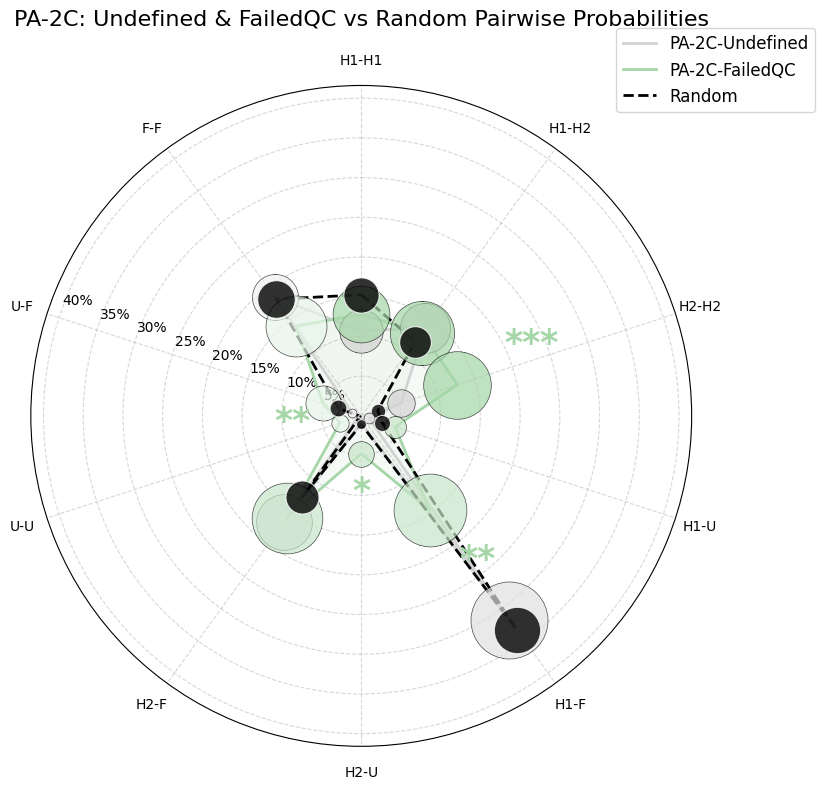


===== 各类别概率之和 =====
Pair Type    Undefined Sim  FailedQC Sim   Random Sum  
----------------------------------------------------
H1-H1         10.70%         12.78%         15.25%
H1-H2         13.69%         12.92%         11.55%
H2-H2          5.30%         12.72%          2.19%
H1-U           1.05%          4.47%          2.77%
H1-F          31.73%         14.64%         33.28%
H2-U           0.90%          4.78%          1.05%
H2-F          16.48%         15.85%         12.60%
U-U            0.42%          2.82%          0.13%
U-F            1.21%          5.06%          3.03%
F-F           18.52%         13.98%         18.15%

全局总和验证:
Undefined 所有类别概率和: 1.000000 (应为1)
FailedQC 所有类别概率和: 1.000000 (应为1)
随机所有类别概率和: 1.000000 (应为1)


In [74]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

# =============================
# 1. 读取模拟数据（Undefined 和 FailedQC）
# =============================
df_u = pd.read_csv("PA-2C-U-p.txt", sep="\t")      # Undefined
df_f = pd.read_csv("PA-2C-F-p.txt", sep="\t")      # FailedQC

pair_names = df_u.columns[1:].tolist()          # 转为列表
sim_matrix_u = df_u[pair_names].values
sim_matrix_f = df_f[pair_names].values

# =============================
# 2. 理论随机分布
# =============================
p_dict = {'H1': 0.3905, 'H2': 0.1479, 'U': 0.0355, 'F': 0.4260}

categories = list(p_dict.keys())
pair_probs = {}
for i, j in itertools.combinations_with_replacement(categories, 2):
    prob = (p_dict[i] ** 2) if i == j else 2 * p_dict[i] * p_dict[j]
    pair_probs[f"{i}-{j}"] = prob

raw_probs = np.array([pair_probs[p] for p in pair_names])
random_prob = raw_probs / raw_probs.sum()   # 随机对照

# =============================
# 3. 模拟均值及标准差
# =============================
sim_mean_u = sim_matrix_u.mean(axis=0)
sim_mean_f = sim_matrix_f.mean(axis=0)
std_u = sim_matrix_u.std(axis=0)
std_f = sim_matrix_f.std(axis=0)

# =============================
# 4. 显著性检验 + 计算随机标准差
# =============================
n_rep = sim_matrix_u.shape[0]
n_sim = 10000
null_matrix = np.random.multinomial(n=n_rep, pvals=random_prob, size=n_sim) / n_rep
null_std = null_matrix.std(axis=0)

p_values_u = []
p_values_f = []
for i in range(len(pair_names)):
    obs_u = sim_matrix_u[:, i]
    obs_f = sim_matrix_f[:, i]
    null = null_matrix[:, i]
    p_u = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs_u.mean() - random_prob[i]))
    p_f = np.mean(np.abs(null - random_prob[i]) >= np.abs(obs_f.mean() - random_prob[i]))
    p_values_u.append(p_u)
    p_values_f.append(p_f)

def sig_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""

sig_labels_u = [sig_star(p) for p in p_values_u]
sig_labels_f = [sig_star(p) for p in p_values_f]

# =============================
# 5. 颜色分组（保持不变）
# =============================
def get_color_group(pair_name):
    if pair_name in ['H1-U', 'H1-F', 'H2-U', 'H2-F']:
        return 'light'
    elif pair_name in ['U-U', 'U-F', 'F-F']:
        return 'lighter'
    else:
        return 'primary'

color_u = 'lightgrey'
color_f = '#A5D6A7'
light_u = '#E0E0E0'
lighter_u = '#F0F0F0'
light_f = '#C8E6C9'
lighter_f = '#E8F5E9'

def get_point_color(pair_name, base_color):
    group = get_color_group(pair_name)
    if base_color == color_u:
        if group == 'light':
            return light_u
        elif group == 'lighter':
            return lighter_u
        else:
            return base_color
    else:   # FailedQC
        if group == 'light':
            return light_f
        elif group == 'lighter':
            return lighter_f
        else:
            return base_color

# =============================
# 6. 绘制雷达图（统一画风）
# =============================
angles = np.linspace(0, 2 * np.pi, len(pair_names), endpoint=False).tolist()
angles += angles[:1]   # 闭合

values_u = sim_mean_u.tolist() + sim_mean_u[:1].tolist()
values_f = sim_mean_f.tolist() + sim_mean_f[:1].tolist()
values_rand = random_prob.tolist() + random_prob[:1].tolist()

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': 'polar'})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# 绘制均值折线 + 填充
ax.plot(angles, values_u, linewidth=2, label='PA-2C-Undefined', color=color_u)
ax.fill(angles, values_u, alpha=0.1, color=color_u)
ax.plot(angles, values_f, linewidth=2, label='PA-2C-FailedQC', color=color_f)
ax.fill(angles, values_f, alpha=0.1, color=color_f)
ax.plot(angles, values_rand, '--', linewidth=2, label='Random', color='black')

# ---------- 圆圈：大小表示标准差 ----------
scale = 500
for i, angle in enumerate(angles[:-1]):
    # Undefined 圆圈
    s_u = (std_u[i] * scale) ** 2
    ax.scatter(angle, sim_mean_u[i], s=s_u,
               color=get_point_color(pair_names[i], color_u),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    # FailedQC 圆圈
    s_f = (std_f[i] * scale) ** 2
    ax.scatter(angle, sim_mean_f[i], s=s_f,
               color=get_point_color(pair_names[i], color_f),
               edgecolor='black', linewidth=0.5, alpha=0.7, zorder=5)
    # Random 圆圈
    s_rand = (null_std[i] * scale) ** 2
    ax.scatter(angle, random_prob[i], s=s_rand,
               color='black', edgecolor='white', linewidth=0.8, alpha=0.8, zorder=5)

# ---------- 显著性星号（放大，置于顶层，动态偏移） ----------
for i, (angle, sig1, sig2) in enumerate(zip(angles[:-1], sig_labels_u, sig_labels_f)):
    if sig1:
        r_pos = sim_mean_u[i] + 0.05 + std_u[i] * 0.5
        ax.text(angle, r_pos, sig1, ha='center', va='bottom',
                fontsize=25, color=color_u, weight='bold', zorder=10)
    if sig2:
        r_pos = sim_mean_f[i] + 0.05 + std_f[i] * 0.5
        ax.text(angle, r_pos, sig2, ha='center', va='bottom',
                fontsize=25, color=color_f, weight='bold', zorder=10)

# 坐标轴设置
ax.set_xticks(angles[:-1])
ax.set_xticklabels(pair_names, fontsize=10, ha='center', va='center')
ax.tick_params(axis='x', pad=8)

def perc_formatter(x, pos):
    return f'{x*100:.0f}%'
ax.yaxis.set_major_formatter(FuncFormatter(perc_formatter))
ax.yaxis.set_tick_params(pad=15, labelsize=10)

# ===== 移动径向刻度标签到 290° =====
ax.set_rlabel_position(290)

# 扩大 y 轴上限，给星号留出空间
max_val = max(max(values_u), max(values_f), max(values_rand))
ax.set_ylim(0, max_val * 1.25)

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=12)
plt.title('PA-2C: Undefined & FailedQC vs Random Pairwise Probabilities', fontsize=16, pad=20)

plt.tight_layout()
plt.savefig("PA_2C_Radar_U_F_circles.svg", dpi=300, transparent=True)
plt.show()

# =============================
# 7. 打印每一类概率之和（不变）
# =============================
print("\n===== 各类别概率之和 =====")
print(f"{'Pair Type':<12} {'Undefined Sim':<14} {'FailedQC Sim':<14} {'Random Sum':<12}")
print("-" * 52)
for i, pair in enumerate(pair_names):
    u_sum = sim_mean_u[i]
    f_sum = sim_mean_f[i]
    rand_sum = random_prob[i]
    print(f"{pair:<12} {u_sum*100:>6.2f}%        {f_sum*100:>6.2f}%        {rand_sum*100:>6.2f}%")

print("\n全局总和验证:")
print(f"Undefined 所有类别概率和: {sim_mean_u.sum():.6f} (应为1)")
print(f"FailedQC 所有类别概率和: {sim_mean_f.sum():.6f} (应为1)")
print(f"随机所有类别概率和: {random_prob.sum():.6f} (应为1)")